# Анализ оптовых продаж аудиотехники

**Компания:** «Карпов Саунд» · **Анализируемый период:** март 2024 года  
**Инструменты:** Python, Pandas, Matplotlib, Seaborn

Компания продаёт аудиотехнику розничным сетям и специализированным магазинам. Клиенты оставляют заявки в CRM, а менеджеры согласовывают их и фиксируют подтверждение или отмену. На время недоступности хранилища анализ выполняю по резервным выгрузкам.

Цель — объяснить динамику заказов, оценить выручку и средний чек, найти невостребованный ассортимент и сравнить вклад менеджеров. Запросы ниже оформлены как рабочие обращения заказчиков в рамках учебного кейса. Описание данных и порядок запуска — в [README.md](README.md).

Сначала собираю и проверяю данные, затем исследую заявки и отмены, после этого рассчитываю коммерческие показатели. Количество заказов считаю по уникальным `order_id`: одна строка выгрузки соответствует товарной позиции. В выручку и средний чек включаю только подтверждённые заказы.

## 1. Подготовка данных

Для анализа нужны три таблицы: позиции заказов (`orders`), клиенты и статусы (`order_status`), каталог с ценами в USD (`products`). Дату заказа и менеджера восстанавливаю из структуры папок, категорию товара — из папки каталога.

Это подготовительный этап: собираю общую основу для следующих расчётов. Папка `data/` с исходными выгрузками и файл `data/usd_rate.txt` должны находиться рядом с ноутбуком.

In [ ]:
# Подключаю библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
from IPython.display import Markdown 

In [ ]:
# Задаю один путь к выгрузкам, чтобы при переносе проекта менять только эту настройку
way = 'data/'


In [ ]:
# СОБИРАЕМ ПУТИ К ФАЙЛАМ В ТРИ РАЗНЫХ СПИСКА
# пустые списки file_paths_*, в которые будут добавляться пути к файлам для трех df
file_paths_orders = []
file_paths_order_status = []
file_paths_products = []
# В переменной path находится текущий путь (папка data), dirs — список подпапок в текущей папке, files — список файлов в них
for path, dirs, files in os.walk(way):
    # Вложенный цикл для перебора файлов в текущей папке
    for file in files:
        # для разных df свои наименования файлов
        if file.endswith('orders.csv'):
            # Построение полного пути к файлу с помощью os.path.join(), объединяя текущий путь path и имя файла file
            file_path = os.path.join(path, file)
            # Добавляем получившийся путь в список
            file_paths_orders.append(file_path) 
        elif file.endswith('order_status.csv'):
            # Построение полного пути к файлу с помощью os.path.join(), объединяя текущий путь path и имя файла file
            file_path = os.path.join(path, file)
            # Добавляем получившийся путь в список
            file_paths_order_status.append(file_path)
        elif file.endswith('products.csv'):
            # Построение полного пути к файлу с помощью os.path.join(), объединяя текущий путь path и имя файла file
            file_path = os.path.join(path, file)
            # Добавляем получившийся путь в список
            file_paths_products.append(file_path) 
print(f'Файлов с заказами: {len(file_paths_orders)}; со статусами: {len(file_paths_order_status)}; с товарами: {len(file_paths_products)}')

# пустые таблицы не должны попасть в расчёты
if not all([file_paths_orders, file_paths_order_status, file_paths_products]):
    raise FileNotFoundError('Не найдены исходные CSV. Проверьте путь way и структуру папки data.')

# объединяем все файлы в три таблицы, добавляя в них новые столбцы с менеджером, датой и категорией
df_orders = pd.DataFrame()
df_order_status = pd.DataFrame()
df_products = pd.DataFrame()
for i in file_paths_orders:
    data = pd.read_csv(i)
    data['manager'] = os.path.basename(os.path.dirname(i))
    data['date'] = os.path.basename(os.path.dirname(os.path.dirname(i)))
    df_orders = pd.concat([df_orders, data])
for i in file_paths_order_status:
    data = pd.read_csv(i)
    df_order_status = pd.concat([df_order_status, data])
for i in file_paths_products:
    data = pd.read_csv(i)
    data['category'] = os.path.basename(os.path.dirname(i))
    df_products = pd.concat([df_products, data])
df_orders = df_orders.sort_values(['order_id', 'product_id'], ascending=True)
df_order_status = df_order_status.sort_values('order_id', ascending=True)
df_products = df_products.sort_values('id', ascending=True)

display(df_orders)
display(df_order_status)
display(df_products)


Файлов с заказами: 178; со статусами: 178; с товарами: 26


,order_id,product_id,quantity,manager,date
23,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11
20,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11
31,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11
25,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11
29,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11
...,...,...,...,...,...
6,ZVTW-19610380,1171,28,Ксения Балалайкина,2024-03-22
9,ZVTW-19610380,1308,4,Ксения Балалайкина,2024-03-22
0,ZVTW-19610380,1476,4,Ксения Балалайкина,2024-03-22
7,ZVTW-19610380,1517,11,Ксения Балалайкина,2024-03-22


,order_id,client_id,status
1,ABID-18767701,44,confirmed
3,ACXS-56511429,24,confirmed
2,AEDO-27030558,22,confirmed
0,AFIH-00611801,43,canceled
0,AFUU-55889181,88,confirmed
...,...,...,...
0,ZRCV-04699238,99,confirmed
0,ZREY-28717532,22,confirmed
2,ZUGP-91810341,33,confirmed
0,ZVIS-81883295,14,confirmed


,id,name,price,category
0,1,"AKG, D5",180.46,Динамический микрофон
1,2,"AKG, D40",85.80,Динамический микрофон
0,3,"AKG, C414 XLII",935.11,Конденсаторный микрофон
1,4,"AKG, C214",356.02,Конденсаторный микрофон
2,5,"AKG, P120",86.13,Конденсаторный микрофон
...,...,...,...,...
73,1673,"Yamaha, NS-C210",86.80,Центральный канал
74,1674,"Yamaha, NS-C210BL",75.98,Центральный канал
75,1675,"Yamaha, NS-C444",165.50,Центральный канал
76,1676,"Yamaha, NS-C700",307.89,Центральный канал


In [5]:
# Сверяю контрольные суммы после сборки таблиц. Техническая проверка
print(f' Сумма по quantity в df_orders: {df_orders.quantity.sum()} \n \
Сумма по client_id в df_order_status: {df_order_status.client_id.sum()} \n \
Сумма по price в df_products: {df_products.price.sum()}')


 Сумма по quantity в df_orders: 85062 
 Сумма по client_id в df_order_status: 18347 
 Сумма по price в df_products: 839000.25


**Результат подготовки.** В исходном выполнении собраны 4 603 товарные строки, 346 заказов со статусами и 1 677 товаров каталога. Эти объёмы использую как ориентир при повторной загрузке тех же выгрузок.

## 2. Динамика заявок

**Руководитель отдела продаж:**
> Подготовь динамику поступивших заявок за март и определи дату, когда их было больше всего. Здесь важно учитывать все заявки, в том числе отменённые.

In [ ]:
df_orders['date'] = pd.to_datetime(df_orders['date'])
# groupby объединяет строки одной даты nunique считает разные номера заказов
orders_per_day = (df_orders.groupby('date', as_index=False)
    .agg(orders_count=('order_id', 'nunique'))
    .sort_values('date'))
display(orders_per_day)

# max находит максимальное число заявок loc оставляет все даты с таким значением
peak_days = orders_per_day.loc[orders_per_day['orders_count'] == orders_per_day['orders_count'].max()]
display(peak_days)


,date,orders_count
0,2024-03-01,22
1,2024-03-02,2
2,2024-03-03,1
3,2024-03-04,10
4,2024-03-05,18
5,2024-03-06,14
6,2024-03-07,14
7,2024-03-08,1
8,2024-03-09,1
9,2024-03-10,3


,date,orders_count
13,2024-03-14,34


**Ответ заказчику.** Больше всего заявок поступило **14 марта 2024 года — 34 заказа**. Пока это максимум по обращениям клиентов. Считать его ростом успешных продаж можно после проверки статусов.

## 3. Нагрузка в течение недели

**Руководитель отдела продаж:**
> Посмотри, как различается поток заявок по дням недели. Нужен ориентир для распределения нагрузки менеджеров.

,weekday,orders_count,weekday_name
0,0,10.75,Пн
1,1,16.25,Вт
2,2,17.50,Ср
3,3,18.25,Чт
4,4,15.00,Пт
5,5,2.00,Сб
6,6,2.00,Вс


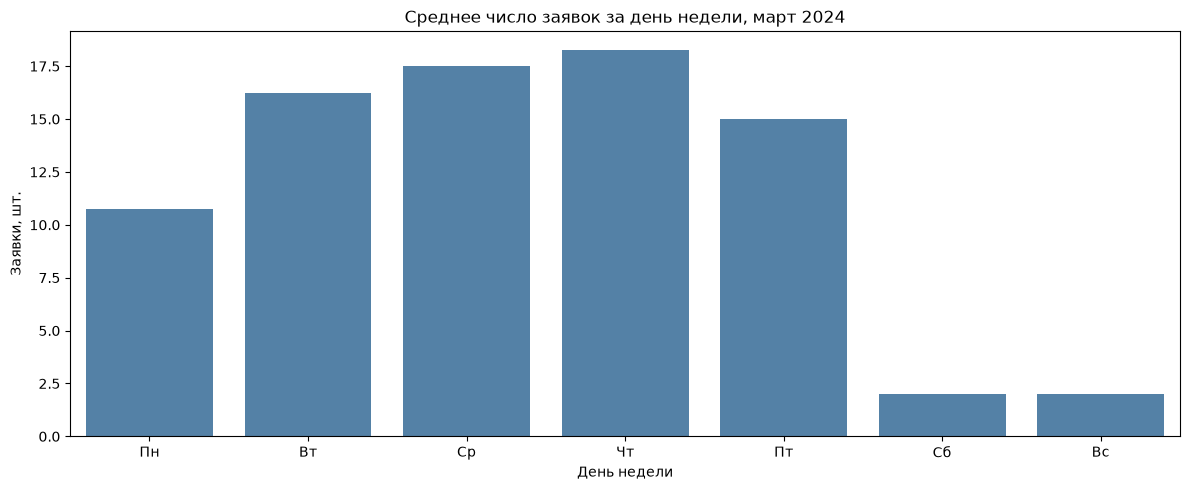

In [ ]:
# вспомогательный срез по дням недели
# dt.day_of_week возвращает номер дня: понедельник — 0, воскресенье — 6
orders_per_day['weekday'] = orders_per_day['date'].dt.day_of_week
# Сравниваю среднее за один день: в марте разное число дней каждого типа
orders_weekdays = orders_per_day.groupby('weekday', as_index=False).agg(orders_count=('orders_count', 'mean'))
days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_names = dict(enumerate(days))
orders_weekdays['weekday_name'] = orders_weekdays['weekday'].map(weekday_names)
orders_per_day['weekday_name'] = orders_per_day['weekday'].map(weekday_names)
display(orders_weekdays)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=orders_weekdays, x='weekday_name', y='orders_count', color='steelblue', ax=ax)
ax.set(title='Среднее число заявок за день недели, март 2024', xlabel='День недели', ylabel='Заявки, шт.')
plt.tight_layout() 
plt.show() 


**Ответ заказчику.** В выходные поступало в среднем **по 2 заявки в день**, в будни — от **10,75 до 18,25**. В марте нагрузка была заметно выше в рабочие дни. Одного месяца недостаточно для вывода об устойчивой сезонности, но этого среза достаточно для первичного планирования смен.

## 4. Нетипичное снижение числа заявок

**Руководитель отдела продаж:**
> Кроме пика 14 марта проверь заметные провалы в рабочие дни. Укажи дату и возможное объяснение, которое нужно учитывать при сравнении.

In [ ]:
# Разворачиваю даты и дни недели в сводный вид, чтобы сравнить одинаковые дни
# pivot меняет расположение данных; reindex задаёт привычный порядок столбцов
# Пропуски сохраняю: они означают, что дата относится к другому дню недели
display(orders_per_day.pivot_table(index='date', columns='weekday_name', values='orders_count', fill_value=' ').reindex(columns=days))


C:\Users\lfox1\AppData\Local\Temp\ipykernel_21844\3499126461.py:4: Pandas4Warning: Using a fill_value that cannot be held in the existing dtype is deprecated and will raise in a future version.
  display(orders_per_day.pivot_table(index='date', columns='weekday_name', values='orders_count', fill_value=' ').reindex(columns=days))


weekday_name,Пн,Вт,Ср,Чт,Пт,Сб,Вс
date,,,,,,,
2024-03-01,,,,,22.0,,
2024-03-02,,,,,,2.0,
2024-03-03,,,,,,,1.0
2024-03-04,10.0,,,,,,
2024-03-05,,18.0,,,,,
2024-03-06,,,14.0,,,,
2024-03-07,,,,14.0,,,
2024-03-08,,,,,1.0,,
2024-03-09,,,,,,1.0,


**Ответ заказчику.** **8 марта поступила 1 заявка**, тогда как в остальные пятницы — от 16 до 22. Дата совпадает с праздничным днём: это возможное объяснение снижения активности.

## 5. Подготовка данных для анализа отмен

Чтобы разобраться в пике заявок, сначала добавляю к товарным строкам клиента и статус заказа.

In [ ]:
# validate='many_to_one' проверяет, что одному заказу соответствует одна запись о статусе
# left сохраняет все товарные строки, чтобы отсутствие статуса было видно при проверке
orders_status = df_orders.merge(df_order_status, on='order_id', how='left', validate='many_to_one')
if orders_status['status'].isna().any(): 
    raise ValueError('У части заказов отсутствует статус: нужно проверить выгрузки.')
orders_status.info() 
display(orders_status.head()) 


<class 'pandas.DataFrame'>
RangeIndex: 4603 entries, 0 to 4602
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    4603 non-null   str           
 1   product_id  4603 non-null   int64         
 2   quantity    4603 non-null   int64         
 3   manager     4603 non-null   str           
 4   date        4603 non-null   datetime64[us]
 5   client_id   4603 non-null   int64         
 6   status      4603 non-null   str           
dtypes: datetime64[us](1), int64(3), str(3)
memory usage: 251.9 KB


,order_id,product_id,quantity,manager,date,client_id,status
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11,44,confirmed
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11,44,confirmed
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11,44,confirmed
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11,44,confirmed
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11,44,confirmed


## 6. Доля отмен

**Руководитель отдела продаж:**
> Оцени, какая доля поступивших за март заявок была отменена. Покажи число отмен и общее число заказов, чтобы было понятно, из чего сложилась доля.

In [ ]:
# Использую таблицу статусов: после объединения статус повторяется в каждой товарной строке
total_orders = df_order_status['order_id'].nunique()
canceled_orders = df_order_status.loc[df_order_status['status'] == 'canceled', 'order_id'].nunique()
cancel_share = canceled_orders / total_orders if total_orders else float('nan')

display(df_order_status['status'].value_counts())
print(f'Доля отменённых заказов: {cancel_share:.2%}')


status
confirmed    309
canceled      37
Name: count, dtype: int64

Доля отменённых заказов: 10.69%


**Ответ заказчику.** Отменено **37 из 346 заказов — 10,69%**. Подтверждено 309 заказов. Это доля заявок по номерам заказов, поэтому размер корзины не влияет на показатель.

## 7. Подтверждения и отмены по датам

**Руководитель отдела продаж:**
> Разбери заявки по статусам на каждый день. Есть ли даты без подтверждённых заказов? Отдельно сравни 13 и 14 марта: хочу понять, что стоит за пиком.

In [ ]:
# Считаю разные заказы в каждой паре «дата — статус»
orders_by_date_status = (orders_status.groupby(['date', 'status'], as_index=False)
    .agg(order_id=('order_id', 'nunique')).sort_values(['date', 'status']))

status_daily = (orders_by_date_status.pivot(index='date', columns='status', values='order_id')
    .reindex(columns=['canceled', 'confirmed']).fillna(0).astype(int))
display(status_daily)

no_confirmed_days = status_daily.index[status_daily['confirmed'] == 0]
print('Даты без подтверждений:', ', '.join(no_confirmed_days.strftime('%Y-%m-%d')))


status,canceled,confirmed
date,,
2024-03-01,2,20
2024-03-02,0,2
2024-03-03,0,1
2024-03-04,0,10
2024-03-05,0,18
2024-03-06,1,13
2024-03-07,1,13
2024-03-08,0,1
2024-03-09,1,0


Даты без подтверждений: 2024-03-09


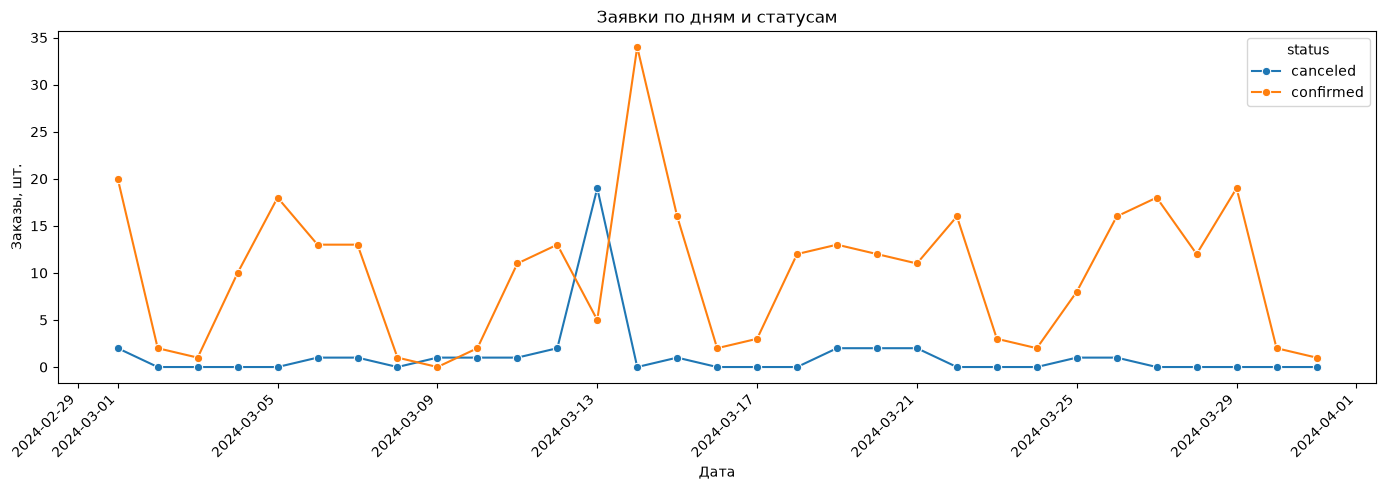

In [ ]:
# Использую отдельную таблицу для графика, не меняя даты в orders_status
status_plot = status_daily.rename_axis(columns='status').stack().rename('order_count').reset_index()

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=status_plot, x='date', y='order_count', hue='status', marker='o', ax=ax)
ax.set(title='Заявки по дням и статусам', xlabel='Дата', ylabel='Заказы, шт.')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Ответ заказчику.** **9 марта** не было ни одного подтверждённого заказа: единственная заявка отменена. **13 марта** из 24 заявок отменено 19, подтверждено 5. **14 марта** подтверждены все 34 заявки. Поэтому перед объяснением пика новым спросом нужно проверить повторные оформления после отмен предыдущего дня.

## 8. Проверка повторных оформлений

**Руководитель отдела продаж:**
> Проверь, есть ли среди заказов 14 марта похожие на заявки 13 марта. Сопоставь клиента, менеджера, число разных товаров и общее количество единиц. Какую часть заказов 14 марта составляют такие совпадения и что это говорит о пике?

In [ ]:
# Сначала перехожу от товарных строк к заказам: нужен один набор характеристик на заказ
# Сохраняю исходный критерий сопоставления: клиент, менеджер, число SKU и число единиц
order_profiles = (orders_status.groupby(['order_id', 'date', 'client_id', 'manager'], as_index=False)
    .agg(product_id=('product_id', 'nunique'), quantity=('quantity', 'sum')))

# Сравниваю Timestamp с Timestamp, чтобы фильтр не зависел от преобразований строк
orders_13 = order_profiles.loc[order_profiles['date'] == pd.Timestamp('2024-03-13')]
orders_14 = order_profiles.loc[order_profiles['date'] == pd.Timestamp('2024-03-14')]
orders_compare = orders_13.merge(orders_14, on=['client_id', 'manager', 'product_id', 'quantity'], how='inner')
display(orders_compare)

# Один заказ может совпасть с несколькими профилями: считаю уникальные номера, а не пары
matched_orders = orders_compare['order_id_y'].nunique()
orders_14_count = orders_14['order_id'].nunique()
print(f'Заказов 13 марта: {orders_13.order_id.nunique()}')
print(f'Похожих заказов 14 марта: {matched_orders} из {orders_14_count}')
if orders_14_count:
    print(f'Доля совпадений: {matched_orders / orders_14_count:.2%}')
else:
    print('За 14 марта нет данных: доля совпадений не определена.')


,order_id_x,date_x,client_id,manager,product_id,quantity,order_id_y,date_y
0,AFIH-00611801,2024-03-13,43,Алексей Саксофонов,11,192,FDEB-71487438,2024-03-14
1,BBFJ-27674101,2024-03-13,73,Ксения Балалайкина,14,294,UETB-44283966,2024-03-14
2,CLBQ-63032648,2024-03-13,60,Виктор Тромбонов,13,205,IECD-18739530,2024-03-14
3,CYJY-07359557,2024-03-13,56,Екатерина Тарелкина,13,316,WNMY-98871151,2024-03-14
4,GHGB-88045656,2024-03-13,7,Ксения Балалайкина,4,42,JUGG-73806170,2024-03-14
5,JEIF-69283221,2024-03-13,94,Виктор Тромбонов,15,207,EPBF-14743479,2024-03-14
6,JQQO-28609300,2024-03-13,93,Виктор Тромбонов,15,252,OWZC-14247946,2024-03-14
7,KJJS-03491897,2024-03-13,66,Алексей Саксофонов,18,399,GRCH-73394464,2024-03-14
8,MIGZ-68487439,2024-03-13,51,Алексей Саксофонов,17,325,BCMM-97072924,2024-03-14
9,NBIO-35476164,2024-03-13,95,Виктор Тромбонов,14,319,NFML-87752700,2024-03-14


Заказов 13 марта: 24
Похожих заказов 14 марта: 16 из 34
Доля совпадений: 47.06%


**Ответ заказчику.** По исходному сопоставлению найдено **16 совпадений из 34 заказов 14 марта — 47,06%**. Почти половина пикового потока могла быть связана с переоформлением заявок предыдущего дня. Предположительно 13 марта был сбой CRM. Нужна более точечная проверка по историям статусов и логам системы.

## 9. Подготовка валютного курса

Для расчёта выручки в рублях добавляю дневной курс USD. Средний курс использую только как справочную величину: сумму заказа пересчитываю по курсу на его дату.

In [ ]:
usd_rate = pd.read_csv(os.path.join(way, 'usd_rate.txt'), sep=',', header=None,
    names=['date', 'currency_rate', 'currency'], parse_dates=['date'])

# Поле currency не нужно при расчёте: в источнике один вид валюты
usd_rate = usd_rate.drop(columns=['currency'])
print(f'Средний курс USD за март: {usd_rate.currency_rate.mean():.2f} руб.')
usd_rate.info()


Средний курс USD за март: 91.70 руб.
<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           31 non-null     datetime64[us]
 1   currency_rate  31 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 628.0 bytes


**Промежуточный результат.** Средний дневной курс из исходного расчёта — **91,70 руб./USD**. Дальше присоединяю курсы по дате, а не умножаю месячные продажи на это среднее.

## 10. Выручка за месяц

**Финансовый директор:**
> Сколько составила выручка за март в рублях? Учитывай только подтверждённые заказы и пересчитывай цены в USD по курсу на дату заказа.

In [ ]:
# Готовлю общий датафрейм: к позициям заказов добавляю цену, название и категорию
# left сохраняет позиции заказов, validate проверяет уникальность товара в каталоге
df_full = orders_status.merge(df_products, left_on='product_id', right_on='id', how='left', validate='many_to_one')
df_full = df_full.rename(columns={'name': 'product_name'}).drop(columns=['id'])
# Курс присоединяю по дате, сохраняя тип datetime в обеих таблицах
df_full = df_full.merge(usd_rate, on='date', how='left', validate='many_to_one')

if df_full[['price', 'currency_rate']].isna().any().any():
    raise ValueError('Не для всех позиций найдены цена и курс. Проверьте источники.')

# Сумма строки = цена в USD × количество × курс на дату заказа
# Для отменённых заявок это потенциальная сумма, в фактическую выручку её не включаю
df_full['revenue'] = df_full['price'] * df_full['quantity'] * df_full['currency_rate']

# loc фильтрует подтверждения; copy создаёт независимую рабочую таблицу для коммерческих метрик
df_confirmed = df_full.loc[df_full['status'] == 'confirmed'].copy()
revenue_month = df_confirmed['revenue'].sum()
display(df_full.head())
print(f'Выручка за март: {revenue_month:,.2f} руб.')


,order_id,product_id,quantity,manager,date,client_id,status,product_name,price,category,currency_rate,revenue
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11,44,confirmed,"Beyerdynamic, DT 990 PRO",158.91,Проводные наушники,90.7493,432629.137890
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11,44,confirmed,"Heco, Stay 300",43.95,Проводные наушники,90.7493,159537.269400
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11,44,confirmed,"JBL, Charge 4",159.13,Беспроводная акустика,90.7493,375464.338834
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11,44,confirmed,"JBL, Xtreme 2",308.70,Беспроводная акустика,90.7493,840429.267300
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11,44,confirmed,"JBL, Live 650BTNC",178.47,Беспроводные наушники,90.7493,453488.771988


Выручка за март: 2,038,231,821.56 руб.


**Ответ заказчику.** Выручка подтверждённых заказов за март составила **2 038 231 821,56 руб.** Отменённые заявки в неё не входят. Это расчёт по ценам и курсам из выгрузок.

## 11. Средний чек

**Финансовый директор:**
> Какова средняя сумма подтверждённого заказа за март? Нужен показатель в рублях, чтобы оценить размер сделки.

In [ ]:
# Средний чек (AOV) = выручка / число подтверждённых заказов
# Уникальные order_id не дают большим корзинам увеличить знаменатель
order_month = df_confirmed['order_id'].nunique()
aov = revenue_month / order_month if order_month else float('nan')
print(f'Подтверждённых заказов: {order_month}; средний чек: {aov:,.2f} руб.')


Подтверждённых заказов: 309; средний чек: 6,596,219.49 руб.


**Ответ заказчику.** Средний чек составил **6 596 219,49 руб.** при 309 подтверждённых заказах. Для оптового бизнеса это средняя сумма заказа, а не средняя цена товара.

## 12. Дневная динамика коммерческих показателей

**Коммерческий директор:**
> Сравни по дням число подтверждённых заказов, выручку и средний чек. Всегда ли рост числа заказов сопровождается ростом выручки? Совпадают ли даты максимальных значений этих показателей?

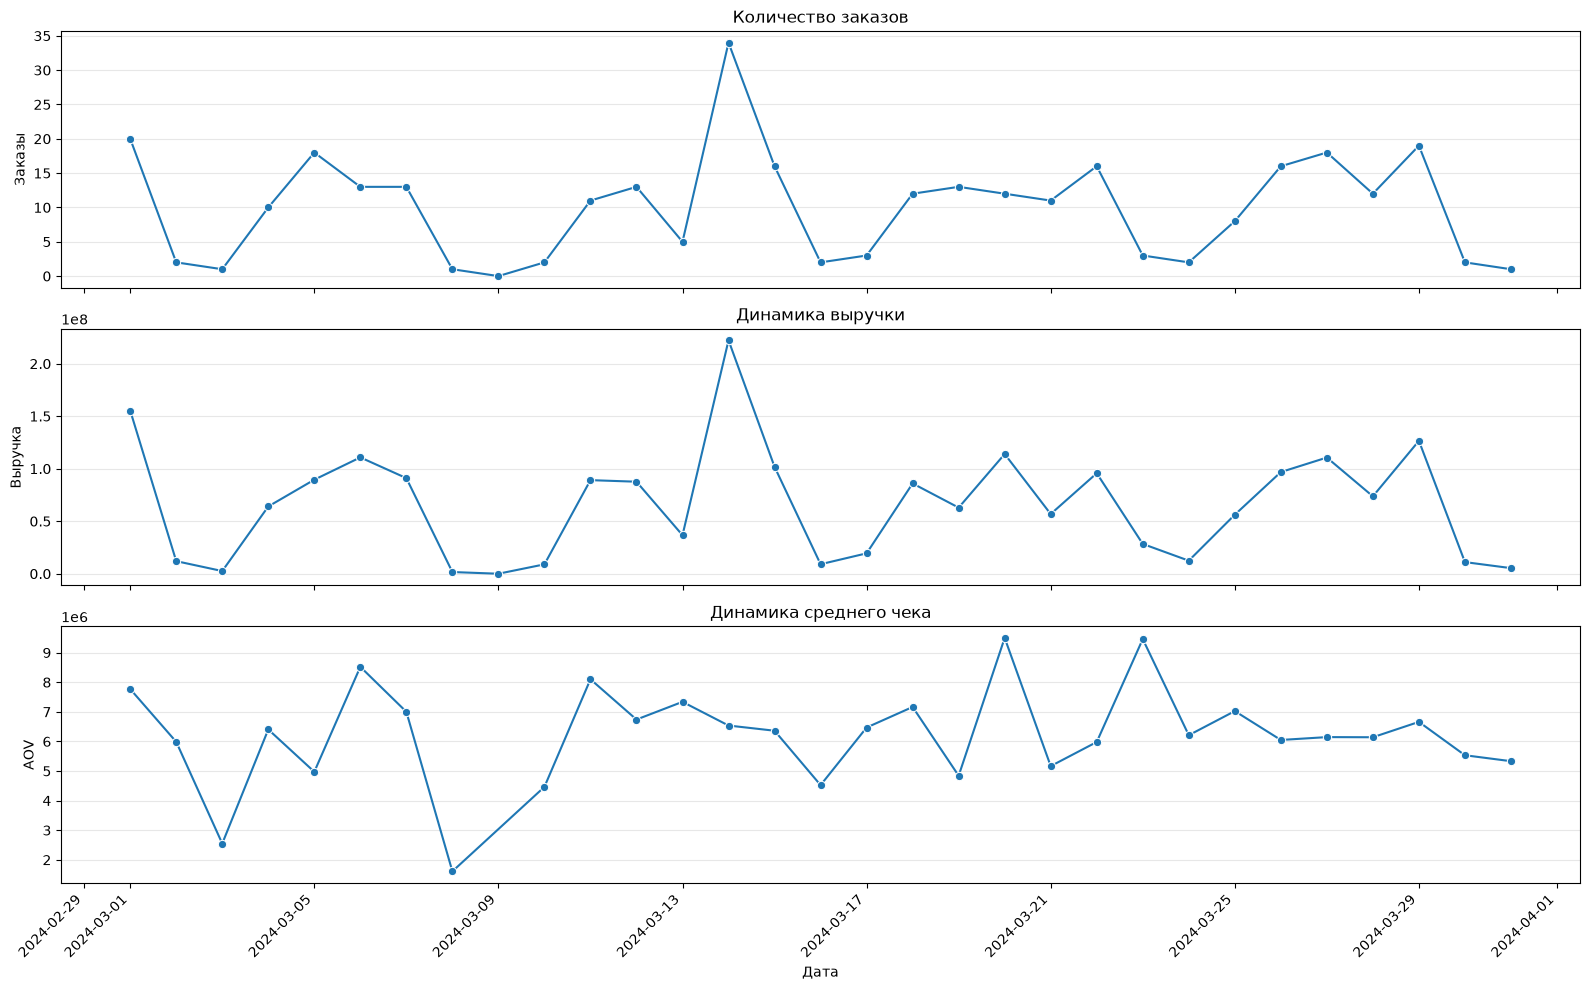

In [ ]:
# Формирую промежуточную таблицу дневных метрик на той же базе, что и месячные показатели
month_dynamic = (df_confirmed.groupby('date', as_index=False)
    .agg(order_count=('order_id', 'nunique'), revenue=('revenue', 'sum')))

# reindex возвращает даты без подтверждений: в них число заказов и выручка равны нулю
month_dynamic = month_dynamic.set_index('date').reindex(orders_per_day['date'], fill_value=0).reset_index()

# При нуле заказов средний чек не определён; replace исключает деление на ноль.
month_dynamic['aov'] = month_dynamic['revenue'] / month_dynamic['order_count'].replace(0, float('nan'))
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

# lineplot строит динамику: разделяю показатели на три графика из-за разных масштабов
# Количество подтверждённых заказов
sns.lineplot(data=month_dynamic, x='date', y='order_count',
             marker='o', ax=axes[0])
axes[0].set_title('Количество заказов')
axes[0].set_ylabel('Заказы')

# Выручка
sns.lineplot(data=month_dynamic, x='date', y='revenue',
             marker='o', ax=axes[1])
axes[1].set_title('Динамика выручки')
axes[1].set_ylabel('Выручка')

# Средний чек
sns.lineplot(data=month_dynamic, x='date', y='aov',
             marker='o', ax=axes[2])
axes[2].set_title('Динамика среднего чека')
axes[2].set_ylabel('AOV')

# Оформление
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
    ax.set_xlabel('')

axes[2].set_xlabel('Дата')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [ ]:
# Формулирую короткий ответ по рассчитанным выше показателям
changes = month_dynamic[['order_count', 'revenue']].diff()
opposite_days = ((changes['order_count'] * changes['revenue']) < 0).sum()

# сохраняю все даты максимума, включая совпадения
max_dates = {}
for metric in ['order_count', 'revenue', 'aov']:
    dates = month_dynamic.loc[month_dynamic[metric] == month_dynamic[metric].max(), 'date']
    max_dates[metric] = ', '.join(dates.dt.strftime('%d.%m.%Y'))
display(Markdown(
    f"**Ответ заказчику.** Дней, когда число подтверждённых заказов и выручка менялись в противоположных направлениях: **{opposite_days}**. "
    f"Максимум числа заказов — **{max_dates['order_count']}**, выручки — **{max_dates['revenue']}**, среднего чека — **{max_dates['aov']}**. "
    "Размер сделки влияет на выручку наряду с числом заказов. 9 марта выручка и число подтверждений равны нулю, средний чек не определён."
))


**Ответ заказчику.** Дней, когда число подтверждённых заказов и выручка менялись в противоположных направлениях: **4**. Максимум числа заказов — **14.03.2024**, выручки — **14.03.2024**, среднего чека — **20.03.2024**. Размер сделки влияет на выручку наряду с числом заказов. 9 марта выручка и число подтверждений равны нулю, средний чек не определён.

## 13. Интерес к брендам

**Руководитель отдела продаж:**
> Товарами скольких брендов интересовались клиенты в марте? Здесь учитывай и подтверждённые, и отменённые заявки: важно само наличие интереса.

In [ ]:
# Название имеет формат «бренд, модель»: выделяю часть до первой запятой
df_full['brand_name'] = df_full['product_name'].apply(lambda x: x.split(',')[0].strip())
print(f'Брендов в заявках: {df_full.brand_name.nunique()}')


Брендов в заявках: 121


**Ответ заказчику.** В заявках встречались товары **121 бренда**. Это охват интереса клиентов; наличие бренда в отменённой заявке ещё не означает состоявшуюся продажу.

## 14. Лидеры среди брендов

**Коммерческий директор:**
> Какой бренд принёс больше всего выручки за март? Сравни его с лидером по числу подтверждённых заказов: совпадают ли они?

In [ ]:
# Считаю выручку и число заказов по брендам только на подтверждениях
# В одном заказе могут быть разные бренды: заказы по брендам нельзя складывать в общий итог
brand_sales = (df_full.loc[df_full['status'] == 'confirmed']
    .groupby('brand_name', as_index=False)
    .agg(revenue=('revenue', 'sum'), order_count=('order_id', 'nunique')))

display(brand_sales.sort_values('revenue', ascending=False))
display(brand_sales.sort_values('order_count', ascending=False).head())


,brand_name,revenue,order_count
46,JBL,2.665961e+08,264
43,Heco,2.388163e+08,229
53,Klipsch,2.039024e+08,205
120,Yamaha,1.658651e+08,218
49,KEF,1.465101e+08,73
...,...,...,...
8,AudioSource,3.388167e+04,1
40,Fosi Audio,3.129419e+04,1
1,ART,2.670040e+04,2
18,Bravo Audio,2.405086e+04,1


,brand_name,revenue,order_count
46,JBL,2.665961e+08,264
43,Heco,2.388163e+08,229
120,Yamaha,1.658651e+08,218
53,Klipsch,2.039024e+08,205
62,Magnat,1.141989e+08,154


In [ ]:
# Формулирую короткий ответ по рассчитанным выше показателям
# Вывожу всех лидеров при равенстве показателей, а не произвольную первую строку
revenue_leaders = brand_sales.loc[brand_sales['revenue'] == brand_sales['revenue'].max()]

order_leaders = brand_sales.loc[brand_sales['order_count'] == brand_sales['order_count'].max()]

revenue_names = ', '.join(revenue_leaders['brand_name'])

order_names = ', '.join(order_leaders['brand_name'])

display(Markdown(
    f"**Ответ заказчику.** По выручке лидирует **{revenue_names}** — **{brand_sales['revenue'].max():,.2f} руб.** "
    f"По числу подтверждённых заказов лидирует **{order_names}** — **{int(brand_sales['order_count'].max())} заказов**. "
    "Вклад бренда в выручку оцениваю вместе с частотой заказов: высокая выручка может складываться из меньшего числа более крупных продаж."
))


**Ответ заказчику.** По выручке лидирует **JBL** — **266,596,053.10 руб.** По числу подтверждённых заказов лидирует **JBL** — **264 заказов**. Вклад бренда в выручку оцениваю вместе с частотой заказов: высокая выручка может складываться из меньшего числа более крупных продаж.

## 15. Востребованность ассортимента

**Руководитель отдела продаж:**
> Сколько товаров каталога хотя бы раз попали в подтверждённые заказы в марте, а сколько не были заказаны? Оцени долю незаказанных позиций.

In [ ]:
# Для каждой позиции каталога проверяю факт хотя бы одной подтверждённой продажи
products_in_orders = df_confirmed['product_id'].unique()
df_products['is_in_orders'] = df_products['id'].isin(products_in_orders).map({True: 'yes', False: 'no'})

display(df_products['is_in_orders'].value_counts())


is_in_orders
yes    1180
no      497
Name: count, dtype: int64

**Ответ заказчику.** Хотя бы раз заказаны **1 180 из 1 677 товаров**. Не были заказаны **497 позиций — 29,64% каталога**. Это кандидаты на дополнительный анализ, но отсутствие продаж за месяц само по себе не обосновывает вывод товара из ассортимента.

## 16. Бренды с низким охватом каталога

**Руководитель отдела продаж:**
> Выдели бренды, у которых в каталоге больше 15 товаров, а более половины позиций ни разу не попали в подтверждённые заказы за март. С них начнём проверку ассортимента.

In [ ]:
# Формирую промежуточную сводную: сколько товаров каждого бренда заказывали и не заказывали
df_products['brand'] = df_products['name'].apply(lambda x: x.split(',')[0].strip())

brand_pivot = (df_products.groupby(['brand', 'is_in_orders'])
    .agg(product_count=('id', 'count')).reset_index()
    .pivot_table(index='brand', columns='is_in_orders', values='product_count', fill_value=0))

# reindex сохраняет оба признака, если в другом периоде один из них не встретится
brand_pivot = brand_pivot.reindex(columns=['no', 'yes'], fill_value=0)
brand_pivot['cnt'] = brand_pivot['no'] + brand_pivot['yes']
brand_pivot['no_part'] = brand_pivot['no'] / brand_pivot['cnt']

# оставляю бренды по согласованным порогам: > 15 товаров и > 50%
display(brand_pivot.query('cnt > 15 and no_part > 0.5'))


is_in_orders,no,yes,cnt,no_part
brand,,,,
Dali,49.0,18.0,67.0,0.731343
KEF,54.0,28.0,82.0,0.658537
Marantz,19.0,3.0,22.0,0.863636
Pioneer,70.0,33.0,103.0,0.679612


**Ответ заказчику.** Критериям соответствуют **Dali — 49 из 67 товаров (73,13%)**, **KEF — 54 из 82 (65,85%)**, **Marantz — 19 из 22 (86,36%)**, **Pioneer — 70 из 103 (67,96%)**. Предлагаю проверить доступность, цены и продвижение этих позиций, прежде чем менять каталог.

## 17. Вклад менеджеров в продажи

**Коммерческий директор:**
> Подготовь отчёт по менеджерам за март: долю каждого в выручке и числе подтверждённых заказов. Покажи лидеров и сотрудников с наименьшим вкладом, чтобы обсудить результаты месяца.

,manager,revenue,order_id,revenue_pct,order_pct
9,Маргарита Камертонова,3.473886e+08,48,17.04,15.53
4,Виктор Тромбонов,3.188999e+08,50,15.65,16.18
8,Максим Барабанов,2.401478e+08,40,11.78,12.94
5,Владимир Ударников,2.084865e+08,31,10.23,10.03
0,Алексей Саксофонов,1.953435e+08,27,9.58,8.74
7,Ксения Балалайкина,1.817621e+08,27,8.92,8.74
6,Екатерина Тарелкина,1.781576e+08,28,8.74,9.06
10,Надежда Гармошкина,1.347836e+08,21,6.61,6.80
1,Анастасия Дудкина,1.234504e+08,20,6.06,6.47
2,Антон Скрипкин,5.150268e+07,7,2.53,2.27


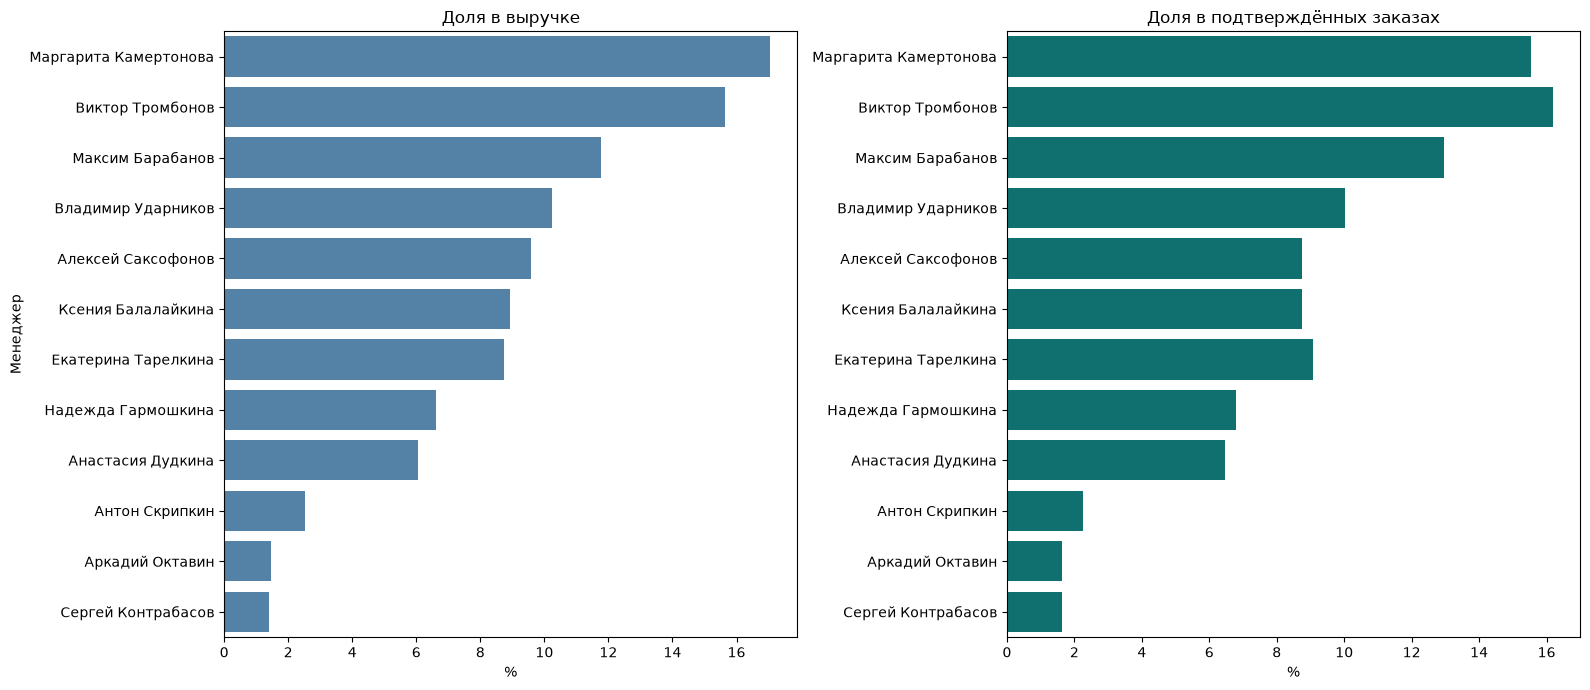

In [ ]:
# Повторно использую общую базу подтверждённых заказов и месячные итоги
manager_stat_pct = (df_confirmed.groupby('manager', as_index=False)
    .agg(revenue=('revenue', 'sum'), order_id=('order_id', 'nunique')))

# Деление на месячный итог переводит вклад менеджера в долю; умножение на 100 — в проценты
manager_stat_pct['revenue_pct'] = manager_stat_pct['revenue'] / revenue_month * 100 if revenue_month else float('nan')
manager_stat_pct['order_pct'] = manager_stat_pct['order_id'] / order_month * 100 if order_month else float('nan')

manager_report = manager_stat_pct.sort_values(['revenue_pct', 'order_pct'], ascending=False)
display(manager_report.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=manager_report, x='revenue_pct', y='manager', color='steelblue', ax=axes[0])
sns.barplot(data=manager_report, x='order_pct', y='manager', color='teal', ax=axes[1])
axes[0].set(title='Доля в выручке', xlabel='%', ylabel='Менеджер')
axes[1].set(title='Доля в подтверждённых заказах', xlabel='%', ylabel='')
plt.tight_layout()
plt.show()


**Ответ заказчику.** По выручке лидирует **Маргарита Камертонова — 17,04%**; по числу подтверждённых заказов — **Виктор Тромбонов, 50 заказов (16,18%)**. Наименьшая доля выручки у **Сергея Контрабасова — 1,40%**; по 5 заказов у него и Аркадия Октавина. У пятого и шестого менеджеров по выручке доли близки — 9,58% и 8,92%, поэтому резкого отрыва первой пятёрки нет. Для решения о премировании дополнительно нужны планы, распределение клиентов и отработанное время.

## Итоги для бизнеса

За март подтверждены 309 из 346 заказов, **выручка** составила 2,038 млрд руб., **средний чек** — 6,596 млн руб. **Доля отмен** — 10,69%.

Пик 14 марта имеет подводные камни: у 16 из 34 заказов совпадают агрегированные характеристики с заявками предыдущего дня. Нужна доп проверка причины массовых отмен 13 марта.

Для первичной проверки ассортимента выделены Dali, KEF, Marantz и Pioneer. По каждому из этих брендов больше половины каталога не продавалось в течение месяца. В отчёте по менеджерам лидеры по выручке и числу заказов различаются; эти метрики следует обсуждать вместе с условиями работы сотрудников.